# Convex hull and planar Delaunay

`convex_hull(points)` wraps scattered points in their closed hull, or with `dimension=2` traces their `x, y` outline; `delaunay_2d(points)` triangulates them in the `x, y` plane, each point keeping its `z`, which turns survey scatter into a terrain. Every decision is an exact geometric predicate, so coplanar and cocircular points need no tolerance. See `doc/hull.md`.

In [1]:
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def draw_surface(ax, points, tris, values, title, cmap='coolwarm', view=(20, 35)):
    """A triangle surface coloured by a point field: PyVista's render embedded
    as an image when GL is available, else a matplotlib Poly3DCollection."""
    if pv is not None:
        faces = np.hstack([np.full((len(tris), 1), 3), tris]).ravel()
        grid = pv.PolyData(points, faces)
        grid.point_data['f'] = values
        pl = pv.Plotter(off_screen=True, window_size=(700, 600))
        pl.add_mesh(grid, scalars='f', cmap=cmap, smooth_shading=True)
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
        ax.axis('off')
    else:
        norm = plt.Normalize(np.nanmin(values), np.nanmax(values))
        coll = Poly3DCollection(points[tris], facecolors=plt.get_cmap(cmap)(norm(values[tris].mean(axis=1))),
                                edgecolor='none')
        ax.add_collection3d(coll)
        lim = np.abs(points).max()
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(*view)
        ax.set_axis_off()
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6)
    ax.set_title(title)

No GL available: rendering with matplotlib.


## The hull of a scan

A cloud of points on and inside a lumpy body, as a scanner might return it. The hull is a closed surface wound outward; its vertices are the extreme points alone, each naming the input point it came from in `hull:point_id`.

{'dimension': 3, 'num_vertices': 385, 'num_facets': 766, 'area': 14.3501, 'volume': 4.6804, 'perimeter': 0.0}
385 of 4000 points are extreme; hull:point_id[:5] = [21 25 26 38 40]


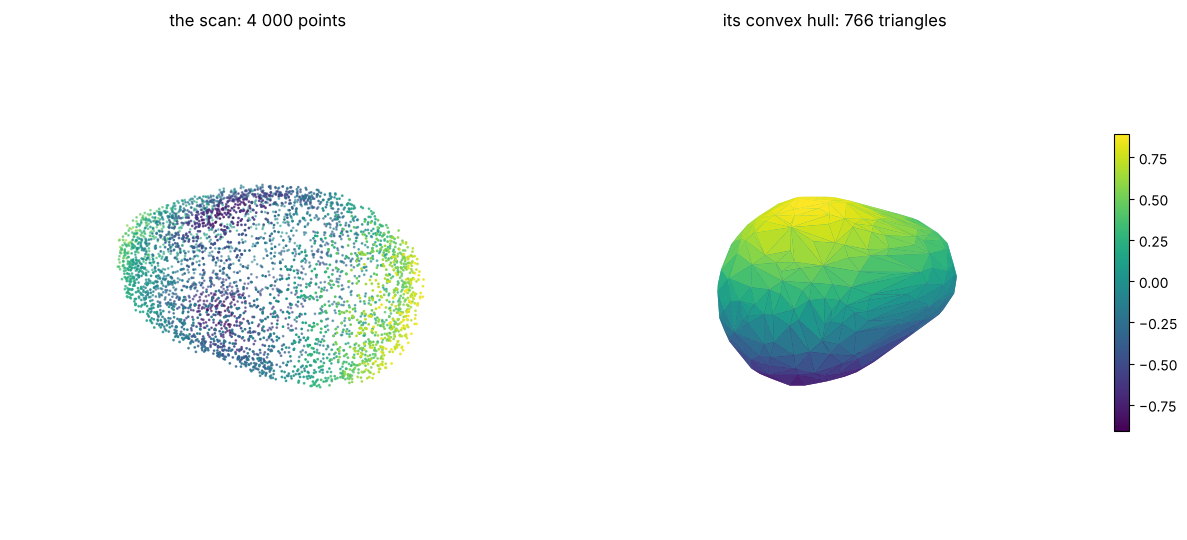

In [2]:
rng = np.random.default_rng(7)
d = rng.normal(size=(4000, 3))
d /= np.linalg.norm(d, axis=1)[:, None]
radius = 1.0 + 0.25 * np.sin(3 * d[:, 0]) * np.cos(2 * d[:, 1])
scale = rng.uniform(0.6, 1.0, size=4000) ** 0.3  # most points near the skin
cloud = d * (radius * scale)[:, None] * [1.4, 1.0, 0.8]

hull, report = mp.convex_hull(cloud, return_report=True)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in report.items()})
ids = hull.point_data['hull:point_id']
print(f'{len(ids)} of {len(cloud)} points are extreme; hull:point_id[:5] = {ids[:5]}')

tris = hull.cells_dict['triangle']
fig = plt.figure(figsize=(13, 5.5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(*cloud.T, s=1, c=np.linalg.norm(cloud, axis=1), cmap='viridis')
ax.set_box_aspect((1.4, 1.0, 0.8)); ax.set_axis_off(); ax.set_title('the scan: 4 000 points')
ax = fig.add_subplot(1, 2, 2, projection=None if pv else '3d')
height = hull.points[:, 2]
draw_surface(ax, hull.points, tris, height, f'its convex hull: {report["num_facets"]} triangles', cmap='viridis')
plt.tight_layout()
plt.show()

## Exact, so degenerate input is not a problem

Every outer point of a lattice lies in the plane of a face. The hull keeps only the 8 corners: faces found coplanar are merged and re-triangulated from their corners, so a point on a facet or an edge never becomes a vertex.

In [3]:
g = np.stack(np.meshgrid(*[np.arange(6.0)] * 3, indexing='ij'), -1).reshape(-1, 3)
lattice_hull, rep = mp.convex_hull(rng.permutation(g), return_report=True)
print(rep)

{'dimension': 3, 'num_vertices': 8, 'num_facets': 12, 'area': 150.0, 'volume': 125.0, 'perimeter': 0.0}


## A footprint in 2-D

`dimension=2` takes the outline of the points' `x, y` projection: a counter-clockwise loop of `line` cells through the strict corners, with its area and perimeter.

{'dimension': 2, 'num_vertices': 37, 'num_facets': 37, 'area': 4.3147, 'volume': 0.0, 'perimeter': 7.6025}


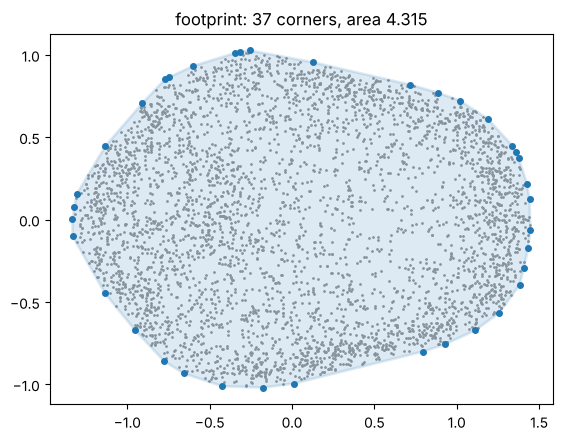

In [4]:
outline, rep2 = mp.convex_hull(cloud, dimension=2, return_report=True)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in rep2.items()})
loop = outline.points[outline.cells_dict['line'][:, 0]]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(cloud[:, 0], cloud[:, 1], s=1, c='0.6')
ax.fill(loop[:, 0], loop[:, 1], facecolor='tab:blue', alpha=0.15, edgecolor='tab:blue', lw=2)
ax.plot(loop[:, 0], loop[:, 1], 'o', color='tab:blue', ms=4)
ax.set_aspect('equal'); ax.set_title(f'footprint: {rep2["num_vertices"]} corners, area {rep2["area"]:.3f}')
plt.show()

## A terrain from survey points

`delaunay_2d` triangulates in `x, y` and keeps every point with its elevation and data, so the point ids match the survey. No point lies inside any triangle's circumcircle (a few are drawn), which is what keeps the triangles as round as the points allow.

{'num_triangles': 1180, 'num_duplicates': 0, 'num_boundary': 18}


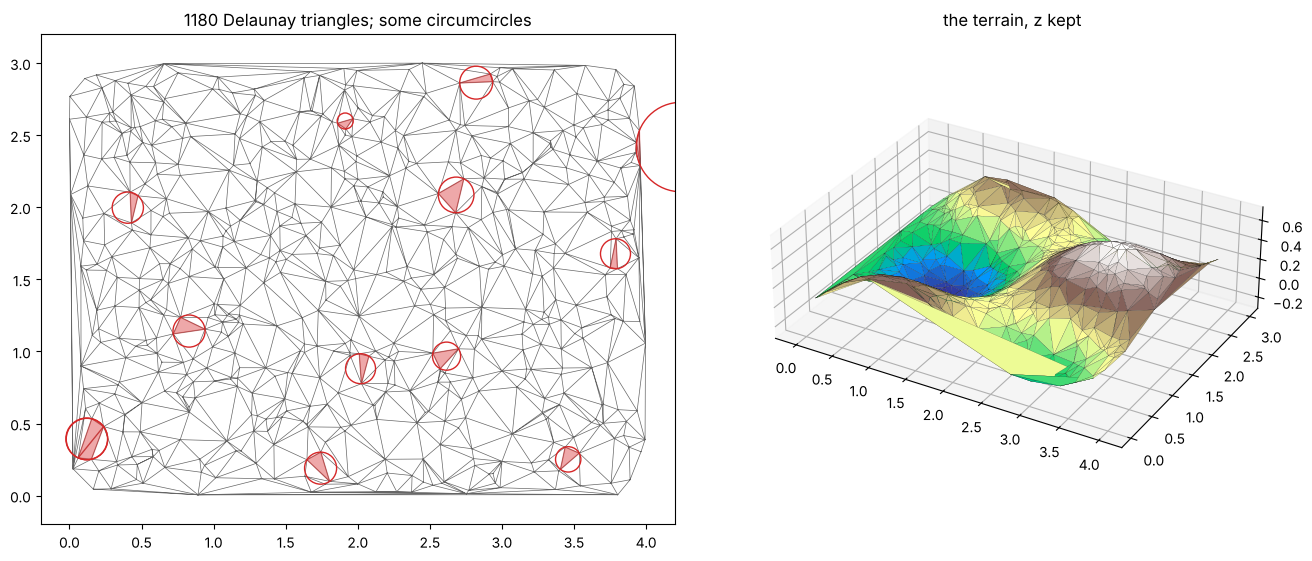

In [5]:
xy = rng.random((600, 2)) * [4.0, 3.0]
z = 0.4 * np.sin(1.5 * xy[:, 0]) * np.cos(2.0 * xy[:, 1]) + 0.1 * xy[:, 0]
survey = mp.Mesh(np.column_stack([xy, z]), [])
survey.point_data['elevation'] = z
terrain, rep3 = mp.delaunay_2d(survey, return_report=True)
print(rep3)
tris = terrain.cells_dict['triangle']

fig = plt.figure(figsize=(14, 5.5))
ax = fig.add_subplot(1, 2, 1)
ax.triplot(xy[:, 0], xy[:, 1], tris, lw=0.5, color='0.4')
for t in tris[::97]:
    a, b, c = xy[t]
    dd = 2 * ((b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0]))
    ux = ((a @ a) * (b[1] - c[1]) + (b @ b) * (c[1] - a[1]) + (c @ c) * (a[1] - b[1])) / dd
    uy = ((a @ a) * (c[0] - b[0]) + (b @ b) * (a[0] - c[0]) + (c @ c) * (b[0] - a[0])) / dd
    ax.add_patch(plt.Circle((ux, uy), np.hypot(*(a - [ux, uy])), fill=False, color='tab:red', lw=1))
    ax.fill(*xy[t].T, color='tab:red', alpha=0.4)
ax.set_aspect('equal'); ax.set_xlim(-0.2, 4.2); ax.set_ylim(-0.2, 3.2)
ax.set_title(f'{rep3["num_triangles"]} Delaunay triangles; some circumcircles')
ax = fig.add_subplot(1, 2, 2, projection='3d')
ax.plot_trisurf(xy[:, 0], xy[:, 1], z, triangles=tris, cmap='terrain', linewidth=0.1, edgecolor='k')
ax.set_title('the terrain, z kept'); ax.set_box_aspect((4, 3, 1.2))
plt.tight_layout()
plt.show()

## In a pipeline, and on the command line

The steps are `ConvexHull` and `Delaunay2D`; the verbs `hull` and `delaunay` in both CLIs.

In [6]:
_, rep4 = mp.apply_operations(survey, [{"Op": "Delaunay2D"}])
print(rep4['steps'][0])
_, rep5 = mp.apply_operations(mp.Mesh(cloud, []), [{"Op": "ConvexHull"}])
print(rep5['steps'][0])
print('meshioplusplus hull scan.xyz hull.stl --json')
print('meshioplusplus delaunay survey.pcd terrain.vtu')

{'op': 'Delaunay2D', 'NumTriangles': 1180.0, 'NumDuplicates': 0.0}
{'op': 'ConvexHull', 'Dimension': 3.0, 'NumVertices': 385.0, 'NumFacets': 766.0, 'Area': 14.350104203226822, 'Volume': 4.680411292303909}
meshioplusplus hull scan.xyz hull.stl --json
meshioplusplus delaunay survey.pcd terrain.vtu
